# Multiple Linear Regression

In [45]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Math

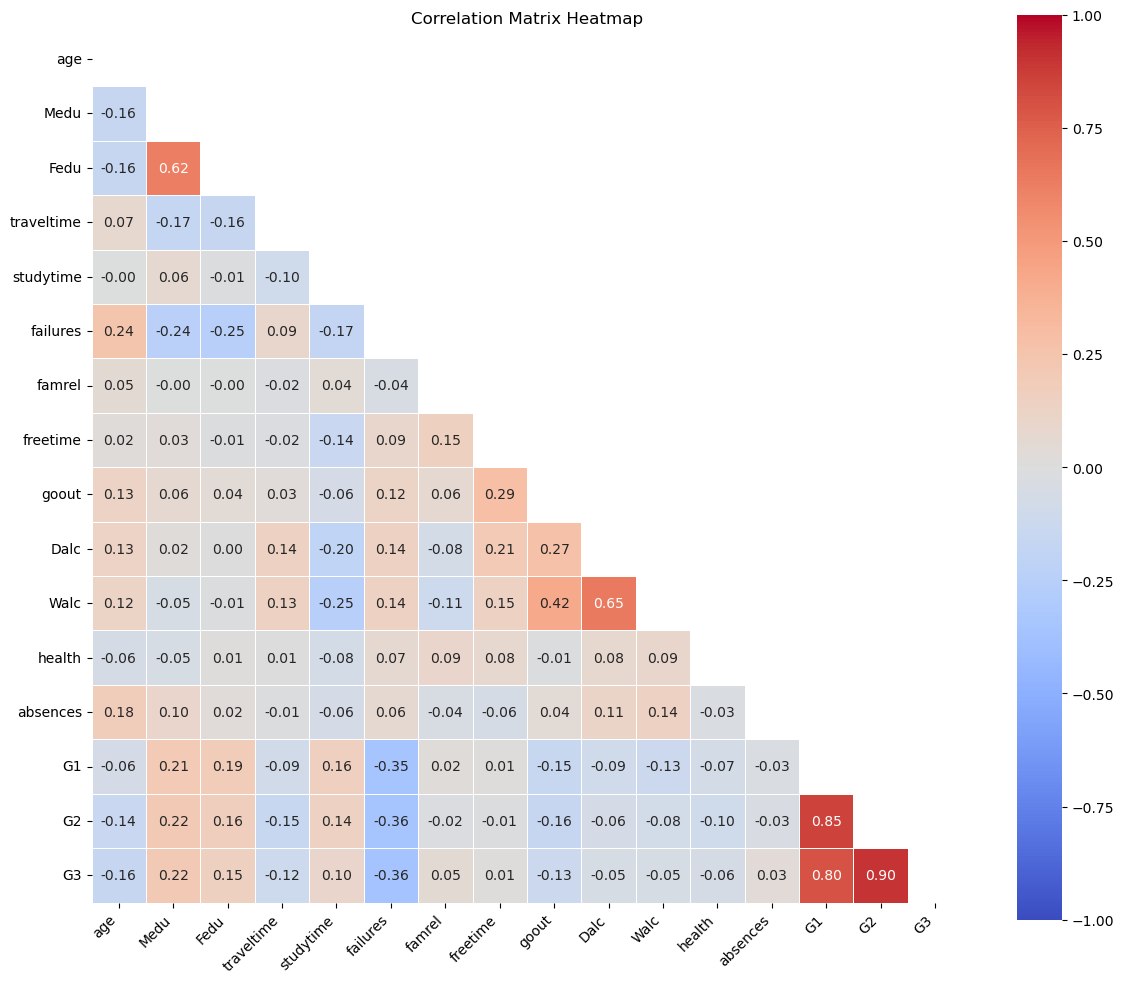

In [33]:
# cols = ['studytime', 'absences', 'G1', 'G2', 'G3'] 
df = pd.read_csv('student-mat.csv', sep=';')
# print(df.head())

plt.figure(figsize=(12, 10))
corr_matrix = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",  # Good divergent color palette for negative (-1) to positive (+1) rules
    vmin=-1,
    vmax=1,  # Forces the color boundaries to represent true correlation limits
    center=0,  # Centers the neutral color at 0 (no correlation)
    square=True,  # Forces the grid cells to be perfectly square
    linewidths=0.5,  # Adds clean dividers between squares
)
plt.title("Correlation Matrix Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
medu = df["Medu"].to_numpy()
fail = df["failures"].to_numpy()
g1 = df["G1"].to_numpy()
g2 = df["G2"].to_numpy()
g3 = df["G3"].to_numpy()

X = np.array([medu, fail, g1, g2]).T
y = g3

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=62)

regressor = LinearRegression()
regressor.fit(X_train, y_train)
print("Learned Coefficients:", regressor.coef_)
print("Learned Intercept:", regressor.intercept_)

Learned Coefficients: [ 0.04501612 -0.22880163  0.16256212  0.97047345]
Learned Intercept: -1.8144657563416402


In [65]:
predictions = regressor.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)
n = len(X)
p = len(X[0])
adj_r2 = 1-((1-r2)*(n-1)/(n-p-1))

print(f'MAE = {mae}')
print(f'RMSE = {rmse}')
print(f'R^2 = {r2}')
print(f'Adjusted R^2 = {adj_r2}')

# display(Math(fr" \Large \text{{MAE}} = {mae:.4f}"))
# display(Math(fr" \Large \text{{RMSE}} = {rmse:.4f}"))
# display(Math(fr" \Large R^2 = {r2:.4f}"))
# display(Math(fr" \Large \text{{Adjusted }} R^2 = {adj_r2:.4f}"))

MAE = 0.8751392412807453
RMSE = 1.604983477171396
R^2 = 0.8548463197045806
Adjusted R^2 = 0.853357564009243


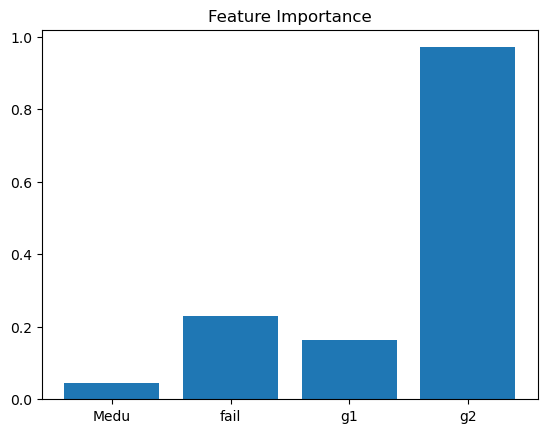

In [73]:
importances = np.abs(regressor.coef_)
feature_names = ['Medu', 'fail', 'g1', 'g2']
plt.bar(feature_names, importances)
plt.title('Feature Importance')
plt.show()

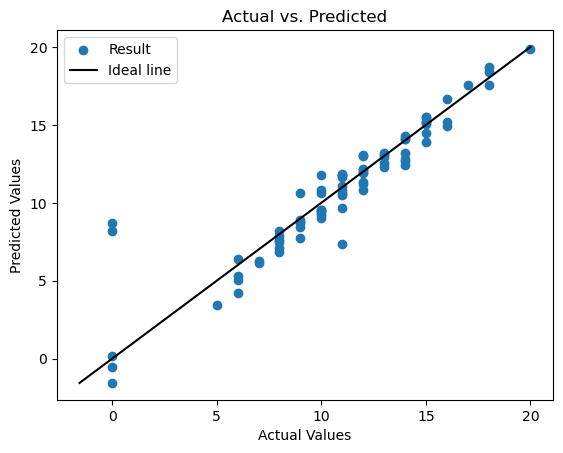

In [30]:
plt.scatter(y_test, predictions, label='Result')
min_val = min(min(y_test), min(predictions))
max_val = max(max(y_test), max(predictions))
plt.plot([min_val, max_val], [min_val, max_val], color = 'black', label='Ideal line')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted')
plt.legend()
plt.show()

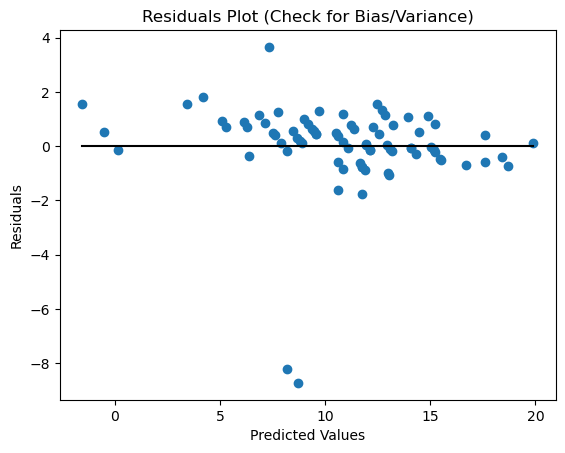

In [31]:
residuals = y_test - predictions
plt.scatter(predictions, residuals)
plt.plot([min(predictions), max(predictions)], [0, 0], color='black')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals Plot (Check for Bias/Variance)')
plt.show()